# 02. Exploratory Data Analysis (EDA)
we explore the cleaned dataset through visualization to understand student burnout risk levels and how academic workload, sleep, and emotional exhaustion relate to risk.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Load cleaned dataset
data_path = Path('../data/processed/cognivault_cleaned_dataset.csv')
df = pd.read_csv(data_path)
print(f"Loaded {df.shape[0]} student records with {df.shape[1]} columns.")
df.head(3)


Loaded 1900 student records with 16 columns.


,institution,degree,year,branch,living_arrangement,study_hours_outside_classes_per_day,academic_tasks_per_week,academic_workload,time_pressure,avg_sleep_hours,wakes_up_tired,physical_activity_days_per_week,difficulty_concentrating,academic_emotional_exhaustion,burnout_risk_score,burnout_risk_level
0,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,8,4,4,5.2,5,2,3,4,57.1,High
1,IIIT Pune,B.Tech,3,CSE,Hostel,3.5,9,4,3,6.0,4,1,3,3,59.7,High
2,IIIT Pune,B.Tech,1,Cyber Security,Hostel,3.5,7,3,3,6.7,2,2,2,1,28.4,Low


### 1. Burnout Risk Level Distribution
Let's see how students are distributed across the four burnout risk levels: Low, Moderate, High, and Critical.


C:\Users\gicsc\AppData\Local\Temp\ipykernel_28628\1337102583.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='burnout_risk_level', order=risk_order, palette=palette)


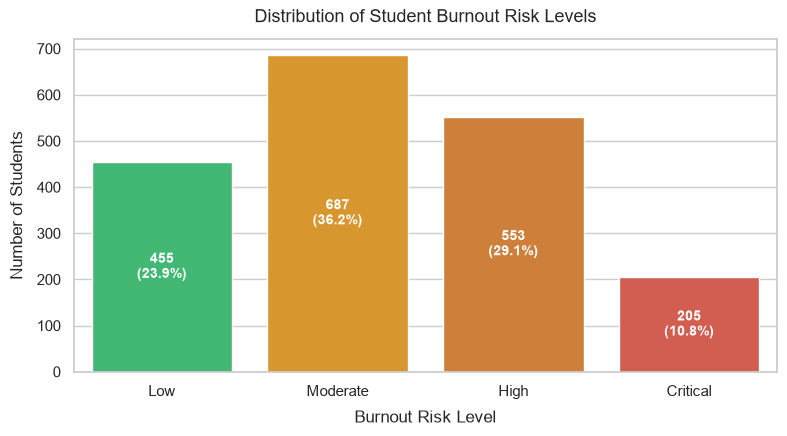

In [2]:
risk_order = ['Low', 'Moderate', 'High', 'Critical']
palette = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=df, x='burnout_risk_level', order=risk_order, palette=palette)
plt.title('Distribution of Student Burnout Risk Levels', fontsize=13, pad=12)
plt.xlabel('Burnout Risk Level', labelpad=8)
plt.ylabel('Number of Students', labelpad=8)

# Add count and percentage labels above bars
total = len(df)
for p in ax.patches:
    height = int(p.get_height())
    pct = (height / total) * 100
    ax.annotate(f'{height}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


**Observation:**
- **Moderate Risk** is the largest group (687 students, 36.2%), followed by **High Risk** (553 students, 29.1%) and **Low Risk** (455 students, 24.0%).
- **Critical Risk** is the smallest group (205 students, 10.8%).
- Because Critical is a minority class, we should evaluate our models using Macro F1-score and use balanced class weighting so the model pays equal attention to all levels.


### 2. Key Lifestyle and Academic Feature Distributions
We look at three important continuous variables: average sleep hours, daily study hours outside class, and academic tasks per week.


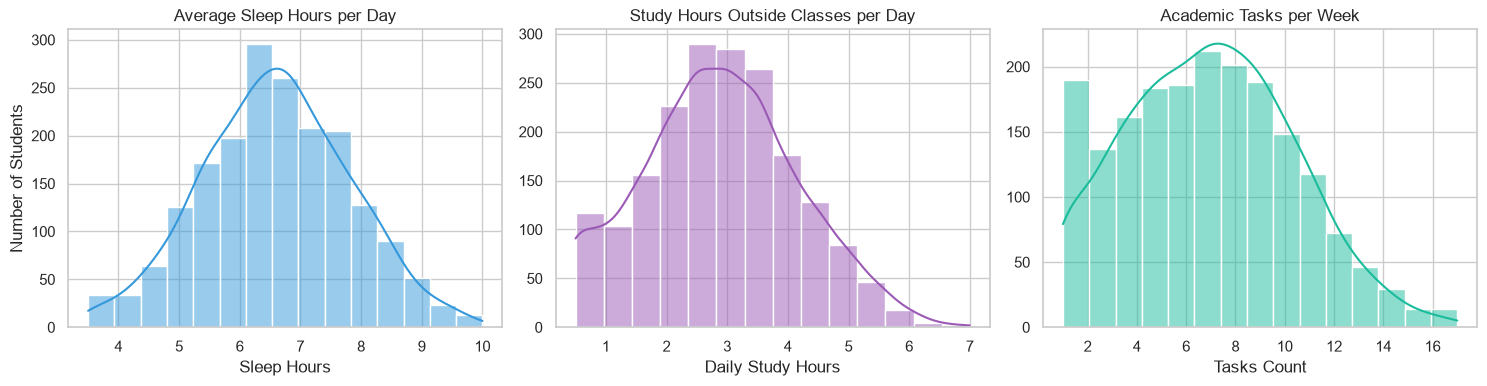

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Sleep hours distribution
sns.histplot(df['avg_sleep_hours'], kde=True, color='#3498db', bins=15, ax=axes[0])
axes[0].set_title('Average Sleep Hours per Day')
axes[0].set_xlabel('Sleep Hours')
axes[0].set_ylabel('Number of Students')

# Study hours distribution
sns.histplot(df['study_hours_outside_classes_per_day'], kde=True, color='#9b59b6', bins=14, ax=axes[1])
axes[1].set_title('Study Hours Outside Classes per Day')
axes[1].set_xlabel('Daily Study Hours')
axes[1].set_ylabel('')

# Academic tasks per week
sns.histplot(df['academic_tasks_per_week'], kde=True, color='#1abc9c', bins=15, ax=axes[2])
axes[2].set_title('Academic Tasks per Week')
axes[2].set_xlabel('Tasks Count')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


**Observation:**
- Most students report sleeping between **5.5 and 7.5 hours per night**, with an average around 6.6 hours.
- Daily study time outside class centers between **2.0 and 5.0 hours**.
- The number of weekly academic tasks ranges from 1 to 17, with most students handling 6 to 12 tasks weekly.


### 3. Comparing Habits Across Burnout Risk Levels
compare sleep hours, emotional exhaustion, and physical activity across the four risk categories.


C:\Users\gicsc\AppData\Local\Temp\ipykernel_28628\3690538508.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='burnout_risk_level', y='avg_sleep_hours', order=risk_order, palette=palette, ax=axes[0])
C:\Users\gicsc\AppData\Local\Temp\ipykernel_28628\3690538508.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='burnout_risk_level', y='academic_emotional_exhaustion', order=risk_order, palette=palette, ax=axes[1])
C:\Users\gicsc\AppData\Local\Temp\ipykernel_28628\3690538508.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='burnout_risk_level', y='physical_activity_days_per_week', order=risk

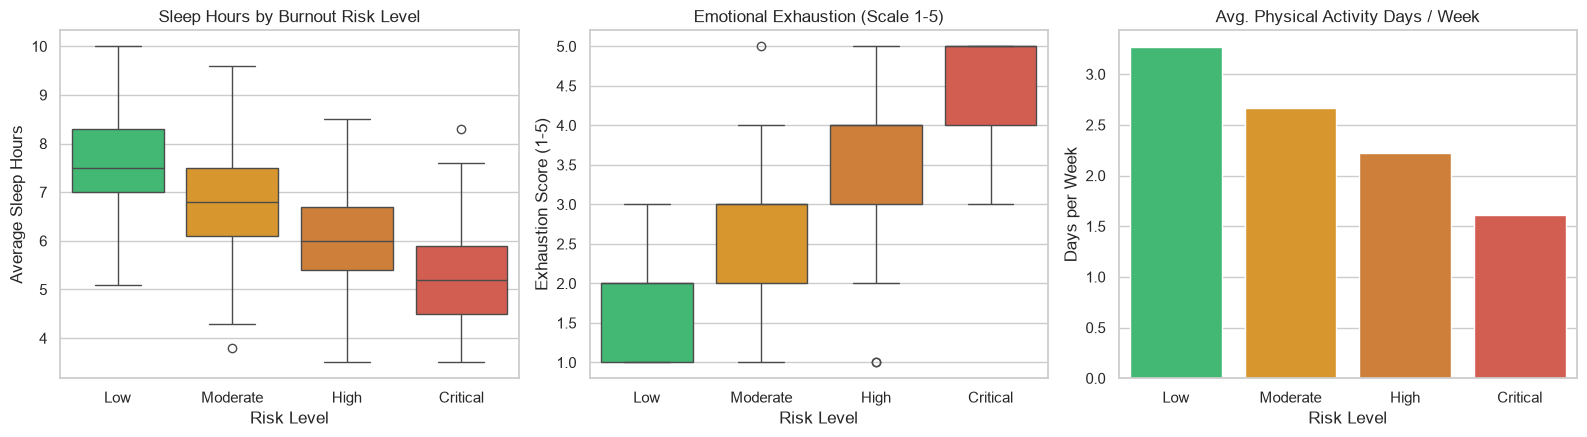

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Sleep hours across risk levels
sns.boxplot(data=df, x='burnout_risk_level', y='avg_sleep_hours', order=risk_order, palette=palette, ax=axes[0])
axes[0].set_title('Sleep Hours by Burnout Risk Level')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Average Sleep Hours')

# Academic emotional exhaustion across risk levels
sns.boxplot(data=df, x='burnout_risk_level', y='academic_emotional_exhaustion', order=risk_order, palette=palette, ax=axes[1])
axes[1].set_title('Emotional Exhaustion (Scale 1-5)')
axes[1].set_xlabel('Risk Level')
axes[1].set_ylabel('Exhaustion Score (1-5)')

# Physical activity days per week
sns.barplot(data=df, x='burnout_risk_level', y='physical_activity_days_per_week', order=risk_order, palette=palette, ci=None, ax=axes[2])
axes[2].set_title('Avg. Physical Activity Days / Week')
axes[2].set_xlabel('Risk Level')
axes[2].set_ylabel('Days per Week')

plt.tight_layout()
plt.show()


**Observation:**
- **Sleep:** Students in the Low risk category average over 7.5 hours of sleep, while High and Critical risk students average 4.5 to 5.5 hours.
- **Emotional Exhaustion:** Low risk students report very low emotional exhaustion (median 1-2), while Critical risk students consistently report high exhaustion (median 4-5).
- **Physical Activity:** Students in the Low risk group average ~3.4 days of physical activity per week, compared to only ~1.5 days for students in the Critical group.


### 4. Correlation Heatmap
We compute Pearson correlations between the numeric survey features and the burnout risk score.


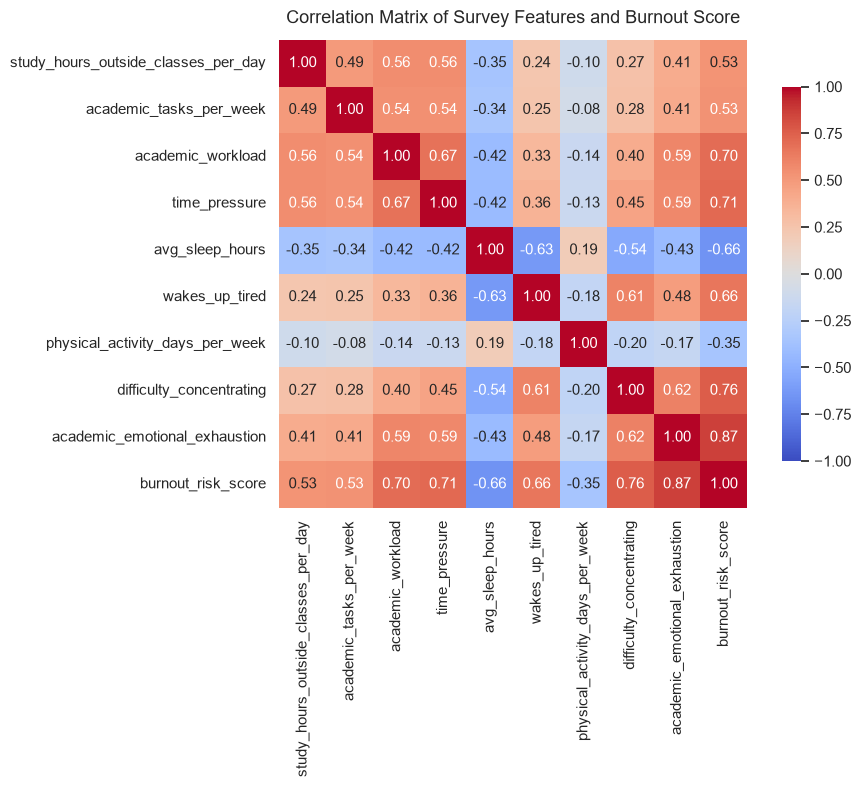

In [5]:
numeric_features = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
    'burnout_risk_score'
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True,
            cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of Survey Features and Burnout Score', fontsize=13, pad=12)
plt.tight_layout()
plt.show()


**Observation:**
- **Strongest Positive Correlations with Burnout Score:**
  - `academic_emotional_exhaustion` ($r = 0.87$)
  - `difficulty_concentrating` ($r = 0.76$)
  - `time_pressure` ($r = 0.71$)
  - `academic_workload` ($r = 0.70$)
- **Strongest Negative Correlation:**
  - `avg_sleep_hours` ($r = -0.66$)
